# 02. EMG Signal Segmentation and Feature Extraction
**Project:** Analysis of Physical Actions Using EMG Signal Classification  
**Target Environment:** Google Colab / Jupyter Notebook  

---

### Notebook Overview
Raw surface EMG signals are high-dimensional, stochastic, and non-stationary. To make them suitable for classification, we segment the signals and extract compact statistical descriptors.

### Feature Extraction Formulation
1. **Google Drive Integration:** Mount Google Drive to load the dataset.
2. **Trial Structure:** According to the experimental protocol, each action recording contains **15 distinct repetitions (trials)** performed consecutively by the subject.
3. **Trial Segmentation:** Each trial signal is segmented into a configurable number of non-overlapping time windows: **$N_{seg}$ segments**.
4. **Statistical Features per Segment:**
   For each segment of each channel, two core statistical features are computed:
   - **Mean ($\mu$):**
     $$\mu = \frac{1}{L} \sum_{t=1}^{L} x(t)$$
   - **Population Variance ($\sigma^2$, $\text{ddof}=0$):**
     $$\sigma^2 = \frac{1}{L} \sum_{t=1}^{L} (x(t) - \mu)^2$$
5. **Feature Ensemble Construction:**
   - With 8 channels, $N_{seg}$ segments, and 2 features per segment, each trial is represented by:
     $$N_f = 8 \text{ channels} \times N_{seg} \text{ segments} \times 2 \text{ features} = 16 \times N_{seg} \text{ features}$$
   - For example, when $N_{seg} = 4$, $N_f = 16 \times 4 = 64$ features per sample.
6. **Separation of Metadata and Features:**
   All metadata (Subject ID, Action Name, Category, Trial Index) is strictly kept in a separate metadata structure and **never** mixed into the numerical feature matrix $X$.

In [1]:
# Step 1: Environment Setup and Library Imports
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11

print("Libraries loaded successfully.")

Libraries loaded successfully.


---
## 1. Google Drive Mounting & Dataset Setup

If your dataset is stored in Google Drive (e.g., from the shared link `https://drive.google.com/drive/folders/1qRhw4-W7QCJVh7oLJjysbSUlKHDFT-sB`):

1. **Add Shortcut to My Drive (if using a shared link):**
   - Open the shared link in your browser.
   - Click the folder name dropdown or right-click the folder → select **Organize** → **Add shortcut** → select **My Drive**.
2. **Mount Google Drive:**
   - Running the code cell below executes `drive.mount('/content/drive')`. Colab will prompt you to authorize access.
3. **Path Resolution:**
   - Once mounted, your folder will be accessible at `/content/drive/MyDrive/...`.
   - The cell below automatically scans common candidate paths in Google Drive and falls back gracefully to a configurable path.

In [2]:
# Step 2: Mount Google Drive and Configure Dataset Path

# Mount Google Drive if running inside Google Colab
try:
    from google.colab import drive
    drive.mount('/content/drive')
    print("Google Drive successfully mounted at /content/drive")
except ImportError:
    print("Not running in Google Colab; using local file system.")

# Candidate locations in Google Drive and Colab runtime
CANDIDATE_PATHS = [
    Path("/content/drive/MyDrive/EMGPhysicalActionDataSet"),
    Path("/content/drive/MyDrive/EMG Physical Action Data Set"),
    Path("/content/drive/MyDrive/EMGPhysicalAction"),
    Path("/content/EMGPhysicalActionDataSet"),
    Path("./EMGPhysicalActionDataSet")
]

# Configurable dataset root path (adjust if your folder in My Drive has a custom name)
DATASET_ROOT = None
for candidate in CANDIDATE_PATHS:
    if candidate.exists() and any(candidate.glob("sub*")):
        DATASET_ROOT = candidate
        break

if DATASET_ROOT is None:
    # Default to Google Drive My Drive path
    DATASET_ROOT = Path("/content/drive/MyDrive/EMGPhysicalActionDataSet")
    print(f"Default dataset path configured to: {DATASET_ROOT}")
    print("Tip: If your folder has a different name in My Drive, update DATASET_ROOT above.")
else:
    print(f"Verified dataset root directory located at: {DATASET_ROOT}")

Mounted at /content/drive
Google Drive successfully mounted at /content/drive
Verified dataset root directory located at: /content/drive/MyDrive/EMGPhysicalActionDataSet


---
## 2. Configurable Parameters & Channel Metadata

We configure `N_SEG` and the experimental protocol parameters.

In [3]:
# Step 3: Configurable Parameters and Protocol Constants

# Number of segments per trial (configurable: 2, 4, 8, etc.)
N_SEG = 4

EXPECTED_TRIALS_PER_FILE = 15
EXPECTED_CHANNELS = 8

CHANNEL_NAMES = [
    "CH1: Right Biceps", "CH2: Right Triceps",
    "CH3: Left Biceps", "CH4: Left Triceps",
    "CH5: Right Thigh", "CH6: Right Hamstring",
    "CH7: Left Thigh", "CH8: Left Hamstring"
]

NORMAL_ACTIONS = [
    "Bowing", "Clapping", "Handshaking", "Hugging", "Jumping",
    "Running", "Seating", "Standing", "Walking", "Waving"
]

AGGRESSIVE_ACTIONS = [
    "Elbowing", "Frontkicking", "Hamering", "Headering", "Kneeing",
    "Pulling", "Punching", "Pushing", "Sidekicking", "Slapping"
]

ALL_ACTIONS = NORMAL_ACTIONS + AGGRESSIVE_ACTIONS

print(f"Segments per trial (N_seg): {N_SEG}")
print(f"Expected feature dimensionality per trial: 16 x {N_SEG} = {16 * N_SEG} features")

Segments per trial (N_seg): 4
Expected feature dimensionality per trial: 16 x 4 = 64 features


---
## 3. Flexible Data Loading & Channel Verification

In [4]:
# Step 4: File Loading and Validation Functions

def read_emg_file(file_path: Path) -> np.ndarray:
    """Reads EMG text/log file and validates exactly 8 numeric columns."""
    file_path = Path(file_path)
    if not file_path.is_file():
        raise FileNotFoundError(f"File not found: {file_path}")

    try:
        df = pd.read_csv(file_path, sep=r'[\s,]+', engine='python', header=None)
        df = df.dropna(how='all', axis=1)
        data = df.to_numpy(dtype=np.float64)
    except Exception as e:
        raise ValueError(f"Error reading {file_path.name}: {e}")

    if data.ndim != 2 or data.shape[1] != EXPECTED_CHANNELS:
        raise ValueError(
            f"Channel validation failed for {file_path.name}: "
            f"Expected {EXPECTED_CHANNELS} channels, found {data.shape[1] if data.ndim == 2 else data.shape}."
        )
    return data


def find_action_file(subject_dir: Path, action_name: str) -> Path:
    """Locates action file in subject directory handling spelling/casing variations."""
    subject_dir = Path(subject_dir)
    variants = [action_name.lower()]
    if action_name.lower() == "hamering":
        variants.append("hammering")
    elif action_name.lower() == "hammering":
        variants.append("hamering")

    search_dirs = [
        subject_dir / "txt",
        subject_dir / "log",
        subject_dir / "Aggressive" / "txt",
        subject_dir / "Normal" / "txt",
        subject_dir / "Aggressive" / "log",
        subject_dir / "Normal" / "log",
        subject_dir
    ]

    for s_dir in search_dirs:
        if s_dir.exists():
            for f in s_dir.rglob("*"):
                if f.is_file() and f.suffix.lower() in [".txt", ".log", ".csv"]:
                    stem = f.stem.lower()
                    for v in variants:
                        if stem == v or stem == f"{v}_data" or stem.startswith(f"{v}_") or stem.endswith(f"_{v}"):
                            return f
    return None

print("File loading and discovery routines verified.")

File loading and discovery routines verified.


---
## 4. Principled Trial Segmentation

Each action file records 15 sequential trials. We divide the time series array into 15 equal-duration trial blocks without synthesizing fake data.

In [5]:
# Step 5: Trial Segmentation Function

def segment_recording_into_trials(signal_data: np.ndarray, num_trials: int = 15, min_samples_per_trial: int = 30) -> list:
    """Divides an action recording array of shape (N_samples, 8) into individual trials."""
    total_samples = signal_data.shape[0]
    required_samples = num_trials * min_samples_per_trial

    if total_samples < required_samples:
        raise ValueError(
            f"Recording has insufficient samples ({total_samples}) to extract {num_trials} trials. "
            f"Minimum required is {required_samples} samples."
        )

    trial_length = total_samples // num_trials
    trials = []

    for t_idx in range(num_trials):
        start_idx = t_idx * trial_length
        end_idx = start_idx + trial_length
        trials.append(signal_data[start_idx:end_idx, :])

    return trials

print("Trial segmentation function configured.")

Trial segmentation function configured.


---
## 5. Segment-Level Feature Extraction ($16 \times N_{seg}$ Features)

For each trial:
1. Divide each channel signal of length $L_{trial}$ into $N_{seg}$ segments.
2. Extract **Mean** ($\mu$) and **Population Variance** ($\sigma^2$, `ddof=0`).
3. Total features $= 8 \times N_{seg} \times 2 = 16 \times N_{seg}$ features.

In [6]:
# Step 6: Feature Extraction from Individual Trials

def extract_trial_features(trial_signal: np.ndarray, n_seg: int = 4) -> np.ndarray:
    """Extracts mean and population variance for each segment across all 8 channels."""
    trial_samples, n_channels = trial_signal.shape
    if trial_samples < n_seg:
        raise ValueError(f"Trial length ({trial_samples}) is shorter than n_seg ({n_seg}).")

    seg_length = trial_samples // n_seg
    features = []

    for ch in range(n_channels):
        channel_data = trial_signal[:, ch]
        for seg_idx in range(n_seg):
            s_start = seg_idx * seg_length
            s_end = s_start + seg_length
            segment = channel_data[s_start:s_end]
            features.extend([np.mean(segment), np.var(segment, ddof=0)])

    feature_vector = np.array(features, dtype=np.float64)
    expected_dim = 16 * n_seg
    if len(feature_vector) != expected_dim:
        raise ValueError(f"Feature vector length mismatch: expected {expected_dim}, got {len(feature_vector)}")
    return feature_vector

print(f"Feature extraction function defined ({16 * N_SEG} features per trial).")

Feature extraction function defined (64 features per trial).


---
## 6. End-to-End Feature Matrix and Metadata Assembly

We process all subjects, actions, and trials to construct:
1. **Feature Matrix $X$:** Pure numeric NumPy array of shape $(N_{samples}, 16 \times N_{seg})$.
2. **Metadata DataFrame:** Capturing Subject ID, Action, Category, and Trial Index separately.

In [7]:
# Step 7: Process Dataset and Extract Feature Matrix

def extract_dataset_features(dataset_root: Path, n_seg: int = 4, num_trials: int = 15):
    """Iterates through all subjects and actions, returning X and separate metadata_df."""
    if not dataset_root.exists():
        raise FileNotFoundError(f"Dataset root does not exist: {dataset_root}")

    subject_dirs = [d for d in dataset_root.iterdir() if d.is_dir() and d.name.lower().startswith("sub")]
    subject_dirs = sorted(subject_dirs, key=lambda d: d.name.lower())

    if not subject_dirs:
        raise FileNotFoundError(f"No subject directories found under {dataset_root}")

    feature_rows = []
    metadata_rows = []

    for s_dir in subject_dirs:
        for action in ALL_ACTIONS:
            category = "Normal" if action in NORMAL_ACTIONS else "Aggressive"
            file_path = find_action_file(s_dir, action)

            if file_path is None:
                raise FileNotFoundError(
                    f"Action file for '{action}' missing in subject '{s_dir.name}'."
                )

            recording_signal = read_emg_file(file_path)
            trials = segment_recording_into_trials(recording_signal, num_trials=num_trials)

            for trial_idx, trial_data in enumerate(trials, start=1):
                feat_vec = extract_trial_features(trial_data, n_seg=n_seg)
                feature_rows.append(feat_vec)
                metadata_rows.append({
                    "Subject": s_dir.name,
                    "Action": action,
                    "Category": category,
                    "Trial": trial_idx
                })

    X = np.vstack(feature_rows)
    metadata_df = pd.DataFrame(metadata_rows)
    return X, metadata_df

# Run extraction
X, metadata_df = extract_dataset_features(DATASET_ROOT, n_seg=N_SEG, num_trials=EXPECTED_TRIALS_PER_FILE)

print("--- Feature Extraction Summary ---")
print(f"Feature matrix X shape: {X.shape} (Samples x Features)")
print(f"Metadata DataFrame shape: {metadata_df.shape}")
print(f"Any NaN values in X: {np.isnan(X).any()}")
print(f"Any Infinite values in X: {np.isinf(X).any()}")

--- Feature Extraction Summary ---
Feature matrix X shape: (1200, 64) (Samples x Features)
Metadata DataFrame shape: (1200, 4)
Any NaN values in X: False
Any Infinite values in X: False


In [8]:
# Step 8: Inspect First 10 Rows of Metadata Table

print("First 10 rows of Metadata table:")
print(metadata_df.head(10).to_string(index=False))

print("\nSample Distribution by Category:")
print(metadata_df["Category"].value_counts().to_string())

First 10 rows of Metadata table:
Subject Action Category  Trial
   sub1 Bowing   Normal      1
   sub1 Bowing   Normal      2
   sub1 Bowing   Normal      3
   sub1 Bowing   Normal      4
   sub1 Bowing   Normal      5
   sub1 Bowing   Normal      6
   sub1 Bowing   Normal      7
   sub1 Bowing   Normal      8
   sub1 Bowing   Normal      9
   sub1 Bowing   Normal     10

Sample Distribution by Category:
Category
Normal        600
Aggressive    600


---
## 7. Visualizing Feature Profiles Across Action Classes

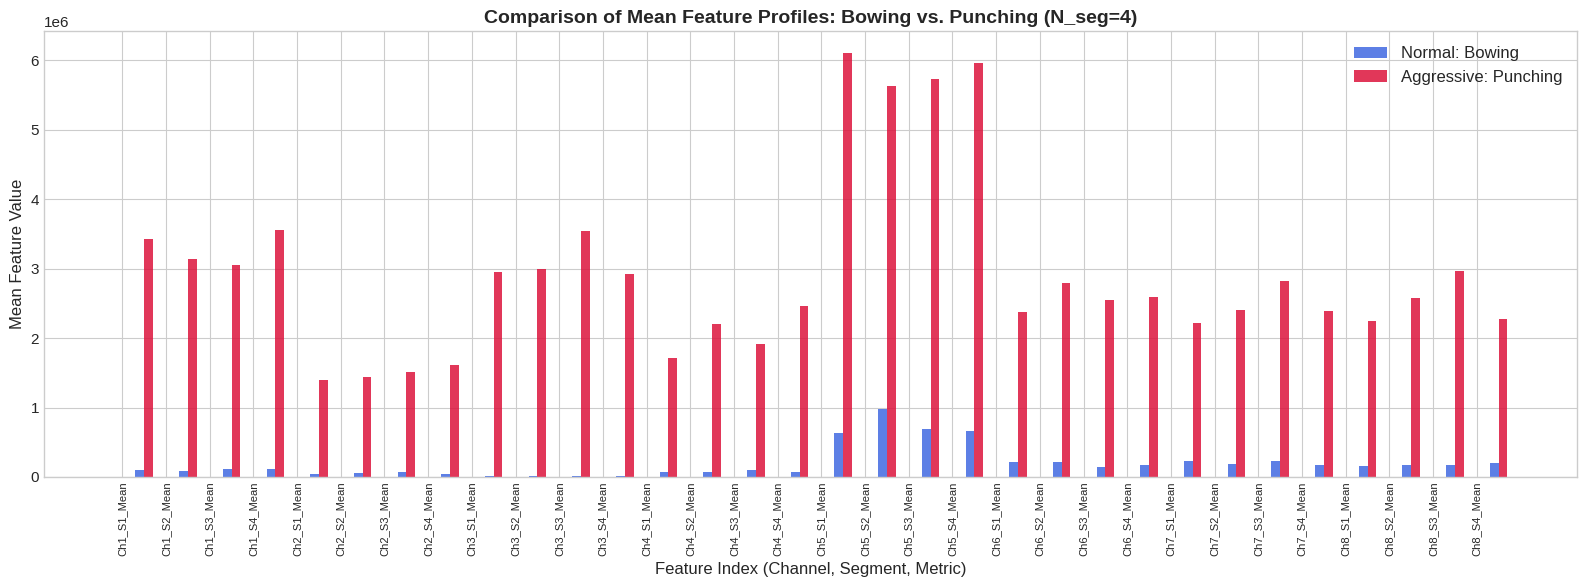

In [9]:
# Step 9: Compare Feature Vectors of Two Actions (Bowing vs. Punching)

action_a = "Bowing"
action_b = "Punching"

idx_a = metadata_df[metadata_df["Action"] == action_a].index
idx_b = metadata_df[metadata_df["Action"] == action_b].index

if len(idx_a) > 0 and len(idx_b) > 0:
    mean_feat_a = np.mean(X[idx_a], axis=0)
    mean_feat_b = np.mean(X[idx_b], axis=0)

    feature_labels = []
    for ch_idx in range(EXPECTED_CHANNELS):
        ch_short = f"Ch{ch_idx+1}"
        for s in range(N_SEG):
            feature_labels.append(f"{ch_short}_S{s+1}_Mean")
            feature_labels.append(f"{ch_short}_S{s+1}_Var")

    plt.figure(figsize=(16, 6))
    x_coords = np.arange(len(mean_feat_a))
    bar_width = 0.4

    plt.bar(x_coords - bar_width/2, mean_feat_a, width=bar_width, label=f"Normal: {action_a}", color='royalblue', alpha=0.85)
    plt.bar(x_coords + bar_width/2, mean_feat_b, width=bar_width, label=f"Aggressive: {action_b}", color='crimson', alpha=0.85)

    plt.title(f"Comparison of Mean Feature Profiles: {action_a} vs. {action_b} (N_seg={N_SEG})", fontsize=14, fontweight='bold')
    plt.xlabel("Feature Index (Channel, Segment, Metric)", fontsize=12)
    plt.ylabel("Mean Feature Value", fontsize=12)
    plt.xticks(x_coords[::2], feature_labels[::2], rotation=90, fontsize=8)
    plt.legend(fontsize=12)
    plt.tight_layout()
    plt.show()
else:
    print(f"Could not find sufficient samples for comparison of {action_a} and {action_b}.")

---
## 8. Summary and Next Steps

- Numerical feature matrix $X$ of shape $(N_{samples}, 16 \times N_{seg})$ constructed.
- Metadata kept strictly separate.
- In `03_label_generation.ipynb`, we generate stable numerical class labels (1 to 20 for multiclass; 0 and 1 for binary).